# SmartSense Dataset — Exploratory Data Analysis

**Assignment 2: Revised Dataset Analysis**

**Team Members:** [Sam Fickle, Harrison Williams]

## Dataset Information

This notebook analyzes the SmartSense smart-home device-control dataset associated with the paper *Accurate Action Recommendation for Smart Home via Two-Level Encoders and Commonsense Knowledge* (2022).

The analysis focuses on the United States (US) training partition, containing 47,516 sequential instances. Each instance consists of 10 events with 5 encoded features per event.

## Dataset Setup

1. Download and extract the SmartSense dataset.
2. Place the extracted `data` folder in the same directory as this Jupyter notebook.
3. Ensure the US dataset files are located in `data/us/`, including:
   - `trn_instance_10.pkl`
   - `vld_instance_10.pkl`
   - `test_instance_10.pkl`
   - `dictionary.py`
   - `routine_device_corpus.txt`

## Running the Analysis

1. Open this notebook using Jupyter Notebook or JupyterLab through Anaconda.
2. Ensure Python has NumPy, pandas, and Matplotlib installed.
3. Select **Kernel → Restart & Run All** to execute the notebook from beginning to end.

The notebook includes descriptive statistics, target-action frequencies, temporal distributions, device-control comparisons, and visualizations. The raw dataset is not included in the submission.

In [ ]:
from collections import Counter, defaultdict
from itertools import combinations
from IPython.display import display

**Data requirement:** `data/us/trn_instance_10.pkl`, `vld_instance_10.pkl`, `test_instance_10.pkl`, `dictionary.py`, and `routine_device_corpus.txt`. The original dictionary-loading cell executes `dictionary.py`; use only a trusted dataset copy.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_folder = "data"

for root, folders, files in os.walk(data_folder):
    level = root.replace(data_folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

data/
    fr/
        dictionary.py
        routine_device_corpus.txt
        test_instance_10.pkl
        trn_instance_10.pkl
        vld_instance_10.pkl
    kr/
        dictionary.py
        routine_device_corpus.txt
        test_instance_10.pkl
        trn_instance_10.pkl
        vld_instance_10.pkl
    sp/
        dictionary.py
        routine_device_corpus.txt
        test_instance_10.pkl
        trn_instance_10.pkl
        vld_instance_10.pkl
    us/
        dictionary.py
        routine_device_corpus.txt
        test_instance_10.pkl
        trn_instance_10.pkl
        vld_instance_10.pkl


In [7]:
import pickle

with open("data/us/trn_instance_10.pkl", "rb") as f:
    train_data = pickle.load(f)

print("Object type:", type(train_data))

Object type: <class 'numpy.ndarray'>


In [8]:
print("Type:", type(train_data))

if hasattr(train_data, "__len__"):
    print("Length:", len(train_data))

Type: <class 'numpy.ndarray'>
Length: 47516


In [9]:
with open("data/us/dictionary.py", "r", encoding="utf-8") as f:
    dictionary_text = f.read()

print(dictionary_text[:5000])

dayofweek_dict = {
    'day:Mon': 0,
    'day:Tue': 1,
    'day:Wed': 2,
    'day:Thu': 3,
    'day:Fri': 4,
    'day:Sat': 5,
    'day:Sun': 6,
}

hour_dict = {
    'time:(0~3)': 0,
    'time:(3~6)': 1,
    'time:(6~9)': 2,
    'time:(9~12)': 3,
    'time:(12~15)': 4,
    'time:(15~18)': 5,
    'time:(18~21)': 6,
    'time:(21~24)': 7,
}

device_dict = {
    'AirConditioner': 0,
    'AirPurifier': 1,
    'Blind': 2,
    'Camera': 3,
    'ClothingCareMachine': 4,
    'Computer': 5,
    'ContactSensor': 6,
    'Dishwasher': 7,
    'Dryer': 8,
    'Elevator': 9,
    'Fan': 10,
    'GarageDoor': 11,
    'Humidifier': 12,
    'Irrigation': 13,
    'LeakSensor': 14,
    'Light': 15,
    'LightSensor': 16,
    'Microwave': 17,
    'MotionSensor': 18,
    'MultiFunctionalSensor': 19,
    'NetworkAudio': 20,
    'None': 21,
    'Other': 22,
    'PresenceSensor': 23,
    'Projector': 24,
    'Refrigerator': 25,
    'RemoteController': 26,
    'RobotCleaner': 27,
    'SecurityPanel': 28,
    'Si

In [10]:
with open("data/us/routine_device_corpus.txt", "r", encoding="utf-8") as f:
    for i in range(10):
        print(repr(f.readline()))

'15 21 15 \n'
'15 21 15 \n'
'34 21 34 \n'
'34 21 34 \n'
'34 21 34 21 34 21 34 \n'
'34 21 34 21 34 21 34 \n'
'21 31 \n'
'21 31 \n'
'31 21 31 \n'
'31 21 31 \n'


In [11]:
print("Dataset shape:", train_data.shape)
print("Data type:", train_data.dtype)

print("\nFirst training instance:")
print(train_data[0])

print("\nShape of first instance:")
print(train_data[0].shape)

Dataset shape: (47516, 10, 5)
Data type: int64

First training instance:
[[  1   0  15   1 108]
 [  1   0  15   0 107]
 [  1   5  15   0 107]
 [  1   6  15   1 108]
 [  2   2  15   0 107]
 [  3   6  15   1 108]
 [  3   6  15   0 107]
 [  3   6  15   1 108]
 [  4   6  15   0 107]
 [  5   2  15   0 107]]

Shape of first instance:
(10, 5)


In [12]:
import ast

with open("data/us/dictionary.py", "r", encoding="utf-8") as f:
    tree = ast.parse(f.read())

dictionary_names = [
    node.targets[0].id
    for node in tree.body
    if isinstance(node, ast.Assign)
    and isinstance(node.targets[0], ast.Name)
]

print(dictionary_names)

['dayofweek_dict', 'hour_dict', 'device_dict', 'device_control_dict']


In [13]:
print("Unique values in each of the 5 columns:")

for col in range(5):
    values = train_data[:, :, col]
    print(
        f"Column {col}:",
        "min =", values.min(),
        "max =", values.max(),
        "unique =", len(set(values.flatten()))
    )

Unique values in each of the 5 columns:
Column 0: min = 0 max = 6 unique = 7
Column 1: min = 0 max = 7 unique = 8
Column 2: min = 0 max = 39 unique = 25
Column 3: min = 0 max = 43 unique = 37
Column 4: min = 0 max = 265 unique = 134


In [14]:
# Execute dictionary.py so we can access its mappings
namespace = {}

with open("data/us/dictionary.py", "r", encoding="utf-8") as f:
    exec(f.read(), namespace)

for name in ["dayofweek_dict", "hour_dict", "device_dict", "device_control_dict"]:
    d = namespace[name]
    print(f"\n{name}")
    print("Number of entries:", len(d))
    print("First 10 entries:")
    
    for key, value in list(d.items())[:10]:
        print(f"  {value}: {key}")
        


dayofweek_dict
Number of entries: 7
First 10 entries:
  0: day:Mon
  1: day:Tue
  2: day:Wed
  3: day:Thu
  4: day:Fri
  5: day:Sat
  6: day:Sun

hour_dict
Number of entries: 8
First 10 entries:
  0: time:(0~3)
  1: time:(3~6)
  2: time:(6~9)
  3: time:(9~12)
  4: time:(12~15)
  5: time:(15~18)
  6: time:(18~21)
  7: time:(21~24)

device_dict
Number of entries: 40
First 10 entries:
  0: AirConditioner
  1: AirPurifier
  2: Blind
  3: Camera
  4: ClothingCareMachine
  5: Computer
  6: ContactSensor
  7: Dishwasher
  8: Dryer
  9: Elevator

device_control_dict
Number of entries: 268
First 10 entries:
  0: AirConditioner:fanspeedDown
  1: AirConditioner:fanspeedUp
  2: AirConditioner:notification
  3: AirConditioner:refresh refresh
  4: AirConditioner:setAcOptionalMode
  5: AirConditioner:setAirConditionerMode
  6: AirConditioner:setCoolingSetpoint
  7: AirConditioner:setFanMode
  8: AirConditioner:setFanOscillationMode
  9: AirConditioner:setThermostatMode


In [17]:
# Reverse the dictionaries so IDs map back to names
device_reverse = {v: k for k, v in namespace["device_dict"].items()}
control_reverse = {v: k for k, v in namespace["device_control_dict"].items()}

print("Device 15:", device_reverse[15])
print("Control 107:", control_reverse[107])
print("Control 108:", control_reverse[108])


Device 15: Light
Control 107: Light:switch off
Control 108: Light:switch on


In [11]:
for col in [2, 3, 4]:
    print(f"\nColumn {col} - first 20 unique values:")
    print(sorted(set(train_data[:, :, col].flatten()))[:20])


Column 2 - first 20 unique values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(15), np.int64(17), np.int64(20), np.int64(22), np.int64(24), np.int64(25), np.int64(27), np.int64(30)]

Column 3 - first 20 unique values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]

Column 4 - first 20 unique values:
[np.int64(0), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(16), np.int64(17), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(27), np.int64(29)]


In [12]:
print("First instance with possible dictionary decoding:\n")

for row in train_data[0]:
    print(
        row,
        "| col2 device:", device_reverse.get(row[2], "N/A"),
        "| col3 device:", device_reverse.get(row[3], "N/A"),
        "| col4 control:", control_reverse.get(row[4], "N/A")
    )

First instance with possible dictionary decoding:

[  1   0  15   1 108] | col2 device: Light | col3 device: AirPurifier | col4 control: Light:switch on
[  1   0  15   0 107] | col2 device: Light | col3 device: AirConditioner | col4 control: Light:switch off
[  1   5  15   0 107] | col2 device: Light | col3 device: AirConditioner | col4 control: Light:switch off
[  1   6  15   1 108] | col2 device: Light | col3 device: AirPurifier | col4 control: Light:switch on
[  2   2  15   0 107] | col2 device: Light | col3 device: AirConditioner | col4 control: Light:switch off
[  3   6  15   1 108] | col2 device: Light | col3 device: AirPurifier | col4 control: Light:switch on
[  3   6  15   0 107] | col2 device: Light | col3 device: AirConditioner | col4 control: Light:switch off
[  3   6  15   1 108] | col2 device: Light | col3 device: AirPurifier | col4 control: Light:switch on
[  4   6  15   0 107] | col2 device: Light | col3 device: AirConditioner | col4 control: Light:switch off
[  5   2  1

In [13]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load US partitions
with open("data/us/trn_instance_10.pkl", "rb") as f:
    train = pickle.load(f)

with open("data/us/vld_instance_10.pkl", "rb") as f:
    val = pickle.load(f)

with open("data/us/test_instance_10.pkl", "rb") as f:
    test = pickle.load(f)

print("Train shape:", train.shape)
print("Validation shape:", val.shape)
print("Test shape:", test.shape)

print("Total instances:", len(train) + len(val) + len(test))

Train shape: (47516, 10, 5)
Validation shape: (6789, 10, 5)
Test shape: (13577, 10, 5)
Total instances: 67882


,Split,Instances,Percentage
0,Training,47516,70.0
1,Validation,6789,10.0
2,Test,13577,20.0


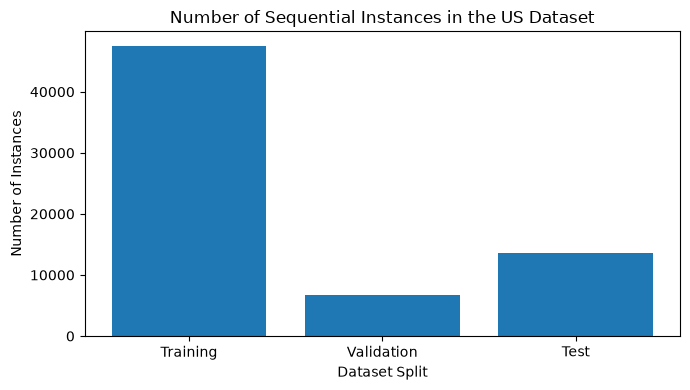

In [14]:
split_df = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Instances": [len(train), len(val), len(test)]
})

split_df["Percentage"] = (
    split_df["Instances"] / split_df["Instances"].sum() * 100
).round(2)

display(split_df)

plt.figure(figsize=(7, 4))
plt.bar(split_df["Split"], split_df["Instances"])

plt.title("Number of Sequential Instances in the US Dataset")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Instances")
plt.tight_layout()
plt.show()

In [15]:
# Reverse dictionaries: numerical ID -> readable label
day_reverse = {v: k.replace("day:", "") 
               for k, v in namespace["dayofweek_dict"].items()}

hour_reverse = {v: k.replace("time:", "") 
                for k, v in namespace["hour_dict"].items()}

device_reverse = {v: k 
                  for k, v in namespace["device_dict"].items()}

control_reverse = {v: k 
                   for k, v in namespace["device_control_dict"].items()}


example = train[0]

example_df = pd.DataFrame({
    "Event": range(1, 11),
    "Day": [day_reverse[x[0]] for x in example],
    "Time Bin": [hour_reverse[x[1]] for x in example],
    "Device": [device_reverse[x[2]] for x in example],
    "Device Control": [control_reverse[x[4]] for x in example]
})

display(example_df)

,Event,Day,Time Bin,Device,Device Control
0,1,Tue,(0~3),Light,Light:switch on
1,2,Tue,(0~3),Light,Light:switch off
2,3,Tue,(15~18),Light,Light:switch off
3,4,Tue,(18~21),Light,Light:switch on
4,5,Wed,(6~9),Light,Light:switch off
5,6,Thu,(18~21),Light,Light:switch on
6,7,Thu,(18~21),Light,Light:switch off
7,8,Thu,(18~21),Light,Light:switch on
8,9,Fri,(18~21),Light,Light:switch off
9,10,Sat,(6~9),Light,Light:switch off


In [16]:
# Flatten 47,516 sequences x 10 events into individual events
events = train.reshape(-1, 5)

device_ids, device_counts = np.unique(events[:, 2], return_counts=True)

device_frequency = pd.DataFrame({
    "Device ID": device_ids,
    "Count": device_counts
})

device_frequency["Device"] = device_frequency["Device ID"].map(device_reverse)

device_frequency = device_frequency.sort_values(
    "Count", ascending=False
)

display(device_frequency.head(10))

,Device ID,Count,Device
22,35,236116,Television
12,15,155542,Light
15,22,19990,Other
0,0,8153,AirConditioner
19,30,8027,SmartLock
10,11,7347,GarageDoor
14,20,6076,NetworkAudio
21,34,5493,Switch
9,10,5329,Fan
20,31,4178,SmartPlug


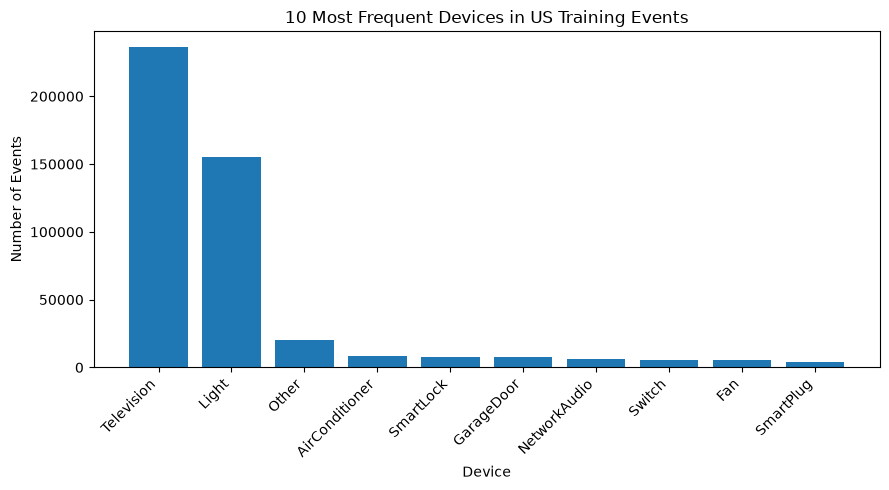

In [17]:
top_devices = device_frequency.head(10)

plt.figure(figsize=(9, 5))
plt.bar(top_devices["Device"], top_devices["Count"])

plt.title("10 Most Frequent Devices in US Training Events")
plt.xlabel("Device")
plt.ylabel("Number of Events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [18]:
control_ids, control_counts = np.unique(events[:, 4], return_counts=True)

control_frequency = pd.DataFrame({
    "Control ID": control_ids,
    "Count": control_counts
})

control_frequency["Device Control"] = (
    control_frequency["Control ID"].map(control_reverse)
)

control_frequency = control_frequency.sort_values(
    "Count", ascending=False
)

display(control_frequency.head(15))

,Control ID,Count,Device Control
126,245,89178,Television:switch off
64,107,75169,Light:switch off
127,246,64273,Television:switch on
120,236,62647,Television:refresh refresh
65,108,61005,Light:switch on
59,102,14158,Light:refresh refresh
79,133,7854,None:location
122,240,6205,Television:setChannel
128,248,6094,Television:volumeDown
110,209,4982,SmartLock:switch on


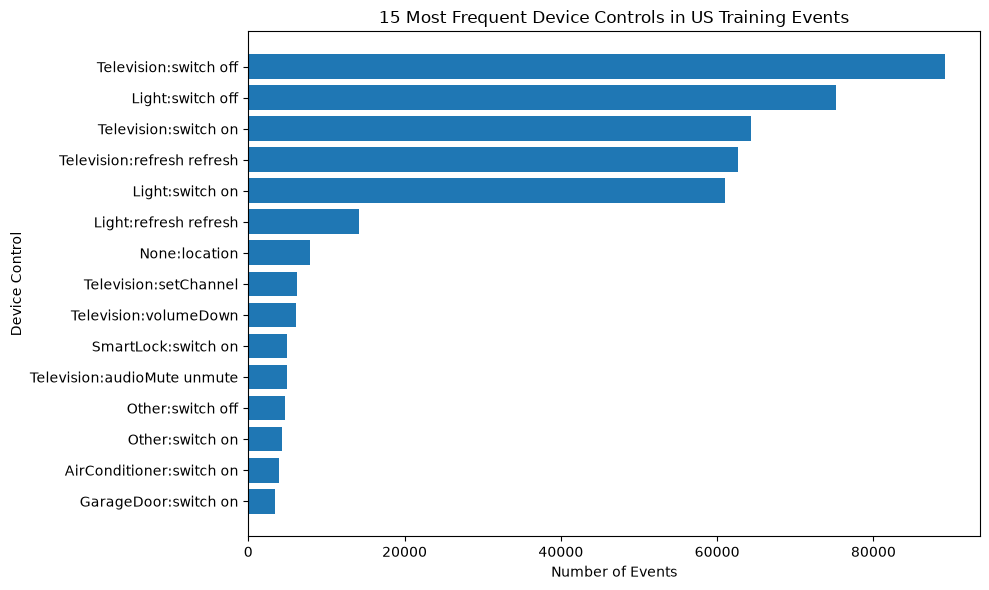

In [19]:
top_controls = control_frequency.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_controls["Device Control"][::-1],
    top_controls["Count"][::-1]
)

plt.title("15 Most Frequent Device Controls in US Training Events")
plt.xlabel("Number of Events")
plt.ylabel("Device Control")
plt.tight_layout()
plt.show()

In [20]:
print("Possible controls in dictionary:", len(control_reverse))
print("Controls observed in training data:", len(control_frequency))

top_10_share = (
    control_frequency.head(10)["Count"].sum()
    / control_frequency["Count"].sum()
    * 100
)

print(f"Percentage of events represented by top 10 controls: {top_10_share:.2f}%")

Possible controls in dictionary: 268
Controls observed in training data: 134
Percentage of events represented by top 10 controls: 82.41%


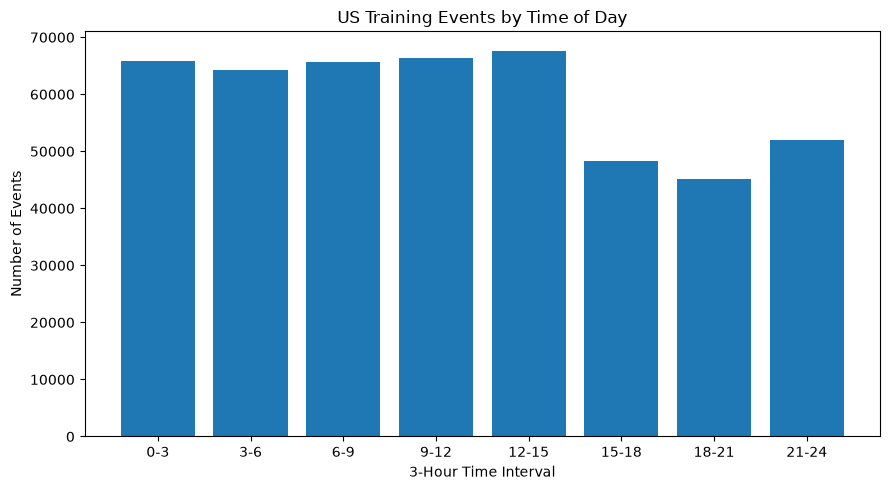

In [21]:
time_counts = pd.Series(events[:, 1]).value_counts().sort_index()

time_labels = [
    "0-3", "3-6", "6-9", "9-12",
    "12-15", "15-18", "18-21", "21-24"
]

plt.figure(figsize=(9, 5))
plt.bar(time_labels, [time_counts.get(i, 0) for i in range(8)])

plt.title("US Training Events by Time of Day")
plt.xlabel("3-Hour Time Interval")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

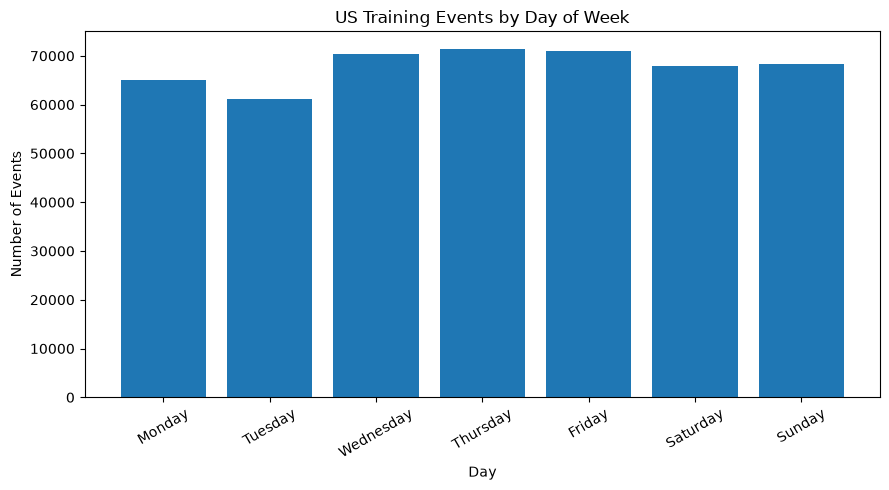

In [22]:
day_counts = pd.Series(events[:, 0]).value_counts().sort_index()

day_labels = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(9, 5))
plt.bar(day_labels, [day_counts.get(i, 0) for i in range(7)])

plt.title("US Training Events by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Events")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
routine_sequences = []

with open("data/us/routine_device_corpus.txt", "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        
        if line:
            sequence = [int(x) for x in line.split()]
            routine_sequences.append(sequence)

routine_lengths = [len(seq) for seq in routine_sequences]

print("Number of routine sequences:", len(routine_sequences))
print("Minimum routine length:", min(routine_lengths))
print("Maximum routine length:", max(routine_lengths))
print("Mean routine length:", np.mean(routine_lengths))
print("Median routine length:", np.median(routine_lengths))

print("\nExample routines:")
for sequence in routine_sequences[:5]:
    print(sequence)

Number of routine sequences: 4957
Minimum routine length: 2
Maximum routine length: 28
Mean routine length: 3.9197095017147467
Median routine length: 3.0

Example routines:
[15, 21, 15]
[15, 21, 15]
[34, 21, 34]
[34, 21, 34]
[34, 21, 34, 21, 34, 21, 34]


## Additional exploratory investigations from SmartSenseObservations

These analyses supplement the shared descriptive EDA with window examples, action repetition, target distributions and categorical analyses.

In [3]:
import numpy as np

# Find two windows that overlap by 9 events
prefix_lookup = {}

for i, window in enumerate(train_data):
    prefix_lookup.setdefault(window[:9].tobytes(), i)

pair = None

for i, window in enumerate(train_data):
    j = prefix_lookup.get(window[1:].tobytes())

    if j is not None and i != j:
        pair = (i, j)
        break

if pair is None:
    print("No overlapping windows found.")
else:
    i, j = pair

    print("First window index:", i)
    print("Second window index:", j)

    print("\nWindow 1:")
    print(train_data[i])

    print("\nWindow 2:")
    print(train_data[j])

    print("\nOverlap verified:",
          np.array_equal(
              train_data[i, 1:],
              train_data[j, :9]
          ))

First window index: 0
Second window index: 37622

Window 1:
[[  1   0  15   1 108]
 [  1   0  15   0 107]
 [  1   5  15   0 107]
 [  1   6  15   1 108]
 [  2   2  15   0 107]
 [  3   6  15   1 108]
 [  3   6  15   0 107]
 [  3   6  15   1 108]
 [  4   6  15   0 107]
 [  5   2  15   0 107]]

Window 2:
[[  1   0  15   0 107]
 [  1   5  15   0 107]
 [  1   6  15   1 108]
 [  2   2  15   0 107]
 [  3   6  15   1 108]
 [  3   6  15   0 107]
 [  3   6  15   1 108]
 [  4   6  15   0 107]
 [  5   2  15   0 107]
 [  6   0  15   1 108]]

Overlap verified: True


In [15]:
routine_path = "data/us/routine_device_corpus.txt"

with open(routine_path, "r", encoding="utf-8") as f:
    lines = [line.strip() for line in f if line.strip()]

device_reverse = {
    v: k for k, v in namespace["device_dict"].items()
}

for line in lines[:5]:
    ids = [int(x) for x in line.split()]
    names = [device_reverse.get(x, f"Unknown({x})") for x in ids]

    print("Raw:", ids)
    print("Decoded:", " → ".join(names))
    print()

Raw: [15, 21, 15]
Decoded: Light → None → Light

Raw: [15, 21, 15]
Decoded: Light → None → Light

Raw: [34, 21, 34]
Decoded: Switch → None → Switch

Raw: [34, 21, 34]
Decoded: Switch → None → Switch

Raw: [34, 21, 34, 21, 34, 21, 34]
Decoded: Switch → None → Switch → None → Switch → None → Switch



In [18]:
# Inspect the relationship between columns 3 and 4

events = train_data.reshape(-1, 5)

mapping = pd.DataFrame({
    "Column 3": events[:, 3],
    "Control ID": events[:, 4]
}).drop_duplicates()

print("Unique column-3 values per control ID:")
print(mapping.groupby("Control ID")["Column 3"].nunique().value_counts())

print("\nExample control mappings:")
mapping["Control Name"] = mapping["Control ID"].map(control_reverse)

display(mapping.sort_values("Control ID").head(25))

Unique column-3 values per control ID:
Column 3
1     92
2     18
3      7
7      4
6      3
5      2
9      1
4      1
10     1
22     1
11     1
13     1
14     1
26     1
Name: count, dtype: int64

Example control mappings:


,Column 3,Control ID,Control Name
17914,5,0,AirConditioner:fanspeedDown
17910,3,0,AirConditioner:fanspeedDown
10150,4,2,AirConditioner:notification
55113,24,3,AirConditioner:refresh refresh
18212,5,3,AirConditioner:refresh refresh
33860,20,3,AirConditioner:refresh refresh
41744,2,3,AirConditioner:refresh refresh
76019,10,3,AirConditioner:refresh refresh
145805,3,3,AirConditioner:refresh refresh
2387,1,3,AirConditioner:refresh refresh


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract the final event of each 10-event instance
targets = train_data[:, -1, :]

print("Original training shape:", train_data.shape)
print("Target events shape:", targets.shape)

# Extract device-control IDs (column 4)
target_actions = targets[:, 4]

# Count how often each target action occurs
action_counts = pd.Series(target_actions).value_counts()

# Create a readable frequency table
target_frequency = pd.DataFrame({
    "Control ID": action_counts.index,
    "Action": [
        control_reverse.get(int(x), "Unknown")
        for x in action_counts.index
    ],
    "Count": action_counts.values,
    "Percentage": (
        action_counts.values / len(target_actions) * 100
    ).round(2)
})

display(target_frequency.head(15))

Original training shape: (47516, 10, 5)
Target events shape: (47516, 5)


,Control ID,Action,Count,Percentage
0,245,Television:switch off,8995,18.93
1,107,Light:switch off,7582,15.96
2,246,Television:switch on,6345,13.35
3,236,Television:refresh refresh,6240,13.13
4,108,Light:switch on,6043,12.72
5,102,Light:refresh refresh,1423,2.99
6,133,None:location,781,1.64
7,248,Television:volumeDown,619,1.30
8,240,Television:setChannel,602,1.27
9,209,SmartLock:switch on,509,1.07


In [20]:
# Number of controls defined in the dictionary
defined_controls = len(control_reverse)

# Number of distinct controls observed as training targets
observed_controls = len(action_counts)

# Share of target events represented by the 10 most common actions
top_10_share = (
    action_counts.head(10).sum()
    / len(target_actions) * 100
)

print("Defined device controls:", defined_controls)
print("Observed training target controls:", observed_controls)
print("Unobserved controls:", defined_controls - observed_controls)
print(f"Top 10 target-action share: {top_10_share:.2f}%")

Defined device controls: 268
Observed training target controls: 123
Unobserved controls: 145
Top 10 target-action share: 82.37%


In [21]:
# Baseline 1: Always predict the most common target action
most_common_action = action_counts.index[0]

majority_accuracy = (
    target_actions == most_common_action
).mean() * 100

# Baseline 2: Predict that the next action repeats the previous action
previous_actions = train_data[:, -2, 4]

repeat_accuracy = (
    target_actions == previous_actions
).mean() * 100

# Additional analysis: same device as previous event
same_device_rate = (
    train_data[:, -1, 2] == train_data[:, -2, 2]
).mean() * 100

print("Most common action:",
      control_reverse.get(int(most_common_action), "Unknown"))

print(f"Most frequent action baseline: {majority_accuracy:.2f}%")
print(f"Repeat previous action baseline: {repeat_accuracy:.2f}%")
print(f"Same device rate: {same_device_rate:.2f}%")

Most common action: Television:switch off
Most frequent action baseline: 18.93%
Repeat previous action baseline: 29.86%
Same device rate: 85.82%


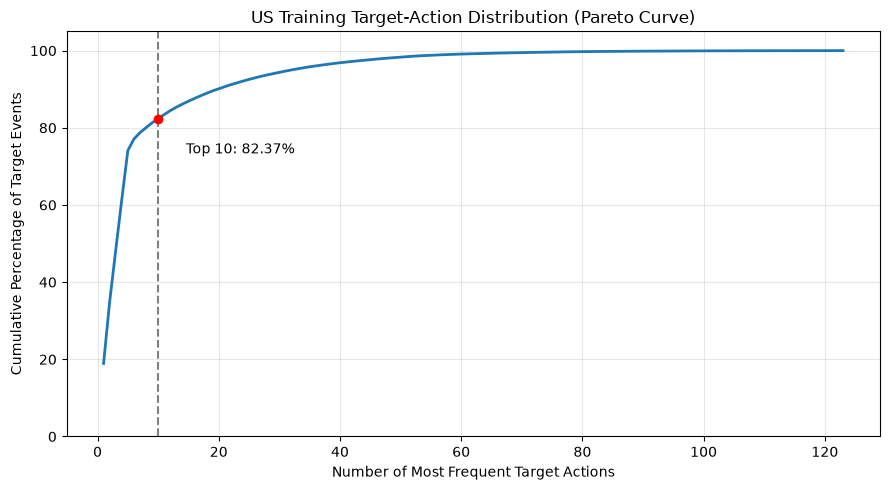

In [22]:
cumulative_share = (
    action_counts.cumsum()
    / action_counts.sum() * 100
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_share) + 1),
    cumulative_share.values,
    linewidth=2
)

plt.scatter(
    10,
    cumulative_share.iloc[9],
    color="red",
    zorder=3
)

plt.axvline(10, linestyle="--", color="gray")

plt.annotate(
    f"Top 10: {cumulative_share.iloc[9]:.2f}%",
    (10, cumulative_share.iloc[9]),
    xytext=(20, -25),
    textcoords="offset points"
)

plt.xlabel("Number of Most Frequent Target Actions")
plt.ylabel("Cumulative Percentage of Target Events")
plt.title("US Training Target-Action Distribution (Pareto Curve)")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
run_lengths = []

for window in train_data:
    actions = window[:, 4]

    current_length = 1

    for i in range(1, len(actions)):
        if actions[i] == actions[i - 1]:
            current_length += 1
        else:
            run_lengths.append(current_length)
            current_length = 1

    run_lengths.append(current_length)

run_lengths = pd.Series(run_lengths)

print("Average run length:", round(run_lengths.mean(), 2))
print("Median run length:", run_lengths.median())
print("Maximum run length:", run_lengths.max())

print("\nRun length distribution:")
display(run_lengths.value_counts().sort_index())

Average run length: 1.35
Median run length: 1.0
Maximum run length: 10

Run length distribution:


1     290127
2      37508
3      10689
4       4352
5       2255
6       1158
7        808
8        501
9        425
10      2883
Name: count, dtype: int64

,Time Interval,Target Count,Percentage
0,00–03,6559,13.80
1,03–06,6431,13.53
2,06–09,6599,13.89
3,09–12,6731,14.17
4,12–15,6807,14.33
5,15–18,4747,9.99
6,18–21,4534,9.54
7,21–24,5108,10.75


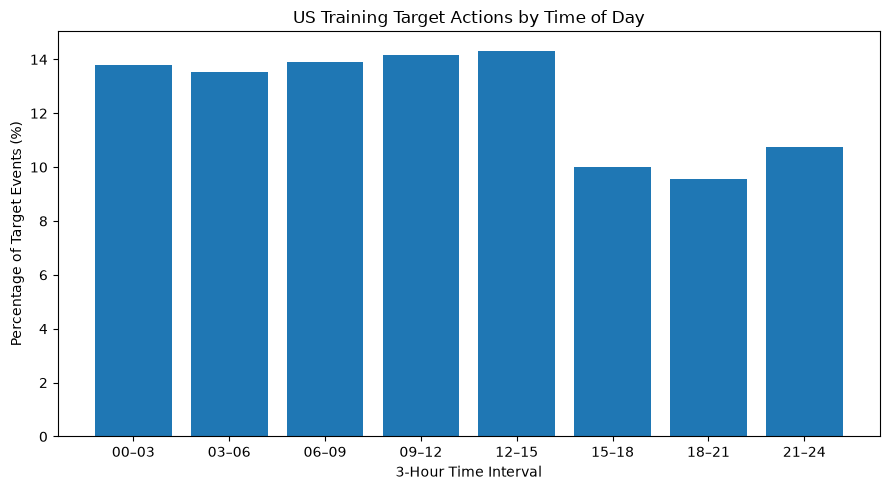

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Final event of each 10-event window
targets = train_data[:, -1, :]

time_labels = [
    "00–03", "03–06", "06–09", "09–12",
    "12–15", "15–18", "18–21", "21–24"
]

time_counts = (
    pd.Series(targets[:, 1])
    .value_counts()
    .reindex(range(8), fill_value=0)
)

time_percent = time_counts / len(targets) * 100

time_table = pd.DataFrame({
    "Time Interval": time_labels,
    "Target Count": time_counts.values,
    "Percentage": time_percent.values.round(2)
})

display(time_table)

plt.figure(figsize=(9, 5))
plt.bar(time_labels, time_percent.values)

plt.title("US Training Target Actions by Time of Day")
plt.xlabel("3-Hour Time Interval")
plt.ylabel("Percentage of Target Events (%)")
plt.tight_layout()
plt.show()

,Day,Target Count,Percentage
0,Monday,6535,13.75
1,Tuesday,6039,12.71
2,Wednesday,6741,14.19
3,Thursday,6978,14.69
4,Friday,7059,14.86
5,Saturday,6947,14.62
6,Sunday,7217,15.19


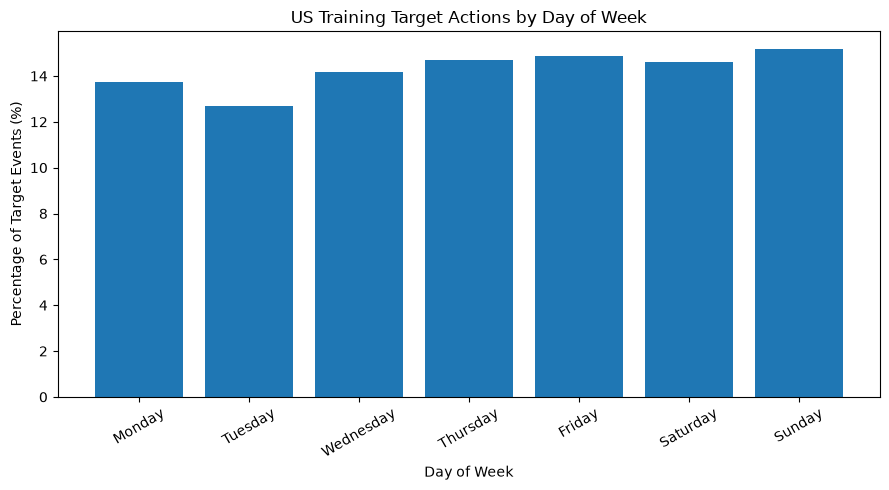

In [25]:
day_labels = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_counts = (
    pd.Series(targets[:, 0])
    .value_counts()
    .reindex(range(7), fill_value=0)
)

day_percent = day_counts / len(targets) * 100

day_table = pd.DataFrame({
    "Day": day_labels,
    "Target Count": day_counts.values,
    "Percentage": day_percent.values.round(2)
})

display(day_table)

plt.figure(figsize=(9, 5))
plt.bar(day_labels, day_percent.values)

plt.title("US Training Target Actions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Percentage of Target Events (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Time ID,0,1,2,3,4,5,6,7
Device,,,,,,,,
Television,13.26,14.29,14.70,13.55,13.47,10.21,9.17,11.36
Light,14.23,12.37,13.27,14.91,16.42,9.98,9.60,9.21
Other,11.99,13.44,14.19,17.24,15.54,8.90,8.90,9.80
SmartLock,21.16,13.78,8.12,6.40,7.50,13.41,13.90,15.74
AirConditioner,16.60,16.36,14.99,8.30,9.17,9.42,11.15,14.00
GarageDoor,17.11,16.41,8.34,8.07,10.85,11.82,9.74,17.66
NetworkAudio,12.42,10.32,17.90,19.52,11.45,7.10,12.74,8.55
Switch,22.52,21.28,11.88,8.69,12.06,8.87,7.80,6.91


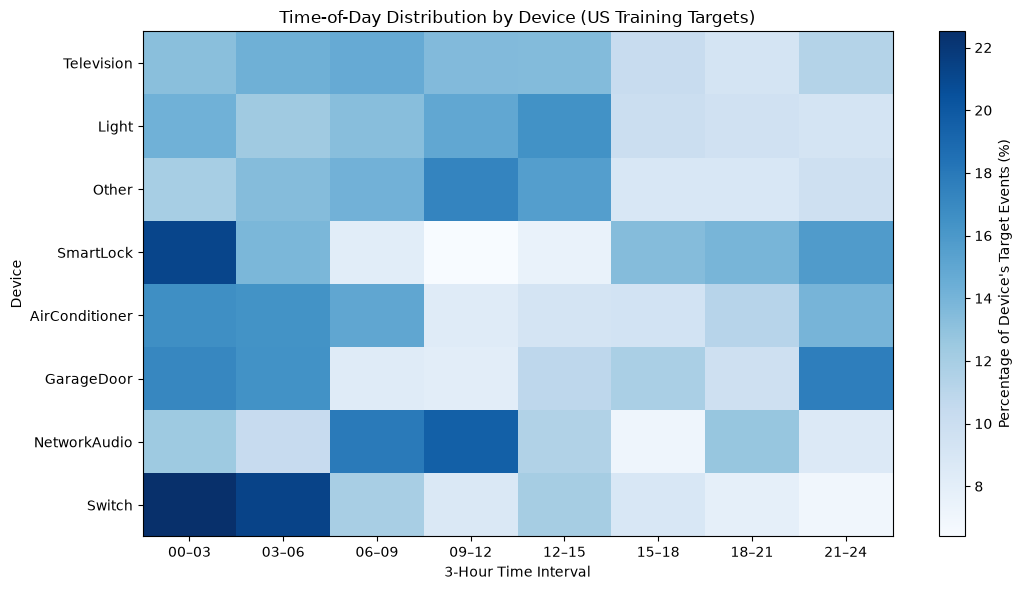

In [26]:
# Decode target device IDs
target_df = pd.DataFrame({
    "Device": [
        device_reverse.get(int(x), f"Unknown({x})")
        for x in targets[:, 2]
    ],
    "Time ID": targets[:, 1],
    "Control ID": targets[:, 4]
})

# Select the 8 most frequent target devices
top_devices = (
    target_df["Device"]
    .value_counts()
    .head(8)
    .index
)

# Count target events by device and time interval
heatmap_counts = pd.crosstab(
    target_df["Device"],
    target_df["Time ID"]
)

heatmap_counts = heatmap_counts.reindex(
    index=top_devices,
    columns=range(8),
    fill_value=0
)

# Normalize each row to 100%
heatmap_percent = (
    heatmap_counts.div(
        heatmap_counts.sum(axis=1),
        axis=0
    ) * 100
)

display(heatmap_percent.round(2))

plt.figure(figsize=(11, 6))

plt.imshow(
    heatmap_percent,
    aspect="auto",
    cmap="Blues"
)

plt.colorbar(label="Percentage of Device's Target Events (%)")

plt.xticks(range(8), time_labels)
plt.yticks(range(len(top_devices)), top_devices)

plt.xlabel("3-Hour Time Interval")
plt.ylabel("Device")
plt.title("Time-of-Day Distribution by Device (US Training Targets)")

plt.tight_layout()
plt.show()

In [27]:
target_df["Action"] = [
    control_reverse.get(int(x), f"Unknown({x})")
    for x in targets[:, 4]
]

most_common_by_time = []

for time_id in range(8):
    subset = target_df[target_df["Time ID"] == time_id]

    counts = subset["Action"].value_counts()

    if len(counts) > 0:
        most_common_by_time.append({
            "Time Interval": time_labels[time_id],
            "Most Common Action": counts.index[0],
            "Count": counts.iloc[0],
            "Percentage Within Interval": round(
                counts.iloc[0] / len(subset) * 100, 2
            )
        })

most_common_time_df = pd.DataFrame(most_common_by_time)

display(most_common_time_df)

,Time Interval,Most Common Action,Count,Percentage Within Interval
0,00–03,Television:switch off,1014,15.46
1,03–06,Television:switch off,1117,17.37
2,06–09,Television:switch off,1323,20.05
3,09–12,Television:switch off,1196,17.77
4,12–15,Television:switch off,1505,22.11
5,15–18,Television:switch off,1191,25.09
6,18–21,Television:switch off,777,17.14
7,21–24,Television:switch off,872,17.07


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Extract target events
targets = train_data[:, -1, :]

# Dictionary of control ID -> control name
control_reverse = {
    v: k
    for k, v in namespace["device_control_dict"].items()
}

# Count defined controls per device
defined_counts = pd.Series([
    name.split(":", 1)[0]
    for name in control_reverse.values()
]).value_counts()

# Find controls actually observed as training targets
observed_ids = set(map(int, targets[:, 4]))

observed_names = [
    control_reverse.get(i, f"Unknown:{i}")
    for i in observed_ids
]

observed_counts = pd.Series([
    name.split(":", 1)[0]
    for name in observed_names
]).value_counts()

# Combine into one table
control_comparison = pd.DataFrame({
    "Defined Controls": defined_counts,
    "Observed Target Controls": observed_counts
}).fillna(0).astype(int)

control_comparison["Coverage (%)"] = (
    control_comparison["Observed Target Controls"]
    / control_comparison["Defined Controls"] * 100
).round(2)

control_comparison = control_comparison.sort_values(
    "Observed Target Controls",
    ascending=False
)

display(control_comparison)

,Defined Controls,Observed Target Controls,Coverage (%)
Television,17,11,64.71
AirConditioner,14,8,57.14
NetworkAudio,11,8,72.73
Refrigerator,15,7,46.67
Light,8,7,87.50
RobotCleaner,15,7,46.67
Other,8,6,75.00
AirPurifier,13,6,46.15
GarageDoor,8,6,75.00
Dryer,11,6,54.55


In [29]:
# Decode target actions
target_action_names = pd.Series([
    control_reverse.get(int(x), f"Unknown:{x}")
    for x in targets[:, 4]
])

# Extract the operation after the device name
operations = target_action_names.str.split(
    ":", n=1
).str[-1].str.lower()

# Classify actions
def classify_action(operation):
    if "refresh" in operation or "status" in operation:
        return "Refresh/Status"
    elif "switch on" in operation or "switch off" in operation:
        return "Switch On/Off"
    else:
        return "Other"

action_categories = operations.apply(classify_action)

category_counts = action_categories.value_counts()

category_table = pd.DataFrame({
    "Category": category_counts.index,
    "Count": category_counts.values,
    "Percentage": (
        category_counts.values / len(targets) * 100
    ).round(2)
})

display(category_table)

,Category,Count,Percentage
0,Switch On/Off,34029,71.62
1,Refresh/Status,8396,17.67
2,Other,5091,10.71


Control,Television:switch off,Light:switch off,Television:switch on,Television:refresh refresh,Light:switch on,Light:refresh refresh,None:location,Television:volumeDown,Television:setChannel,SmartLock:switch on
Device,,,,,,,,,,
Television,8995,0,6345,6240,0,0,0,619,602,0
Light,0,7582,0,0,6043,1423,0,0,0,0
Other,0,0,0,0,0,0,781,0,0,0
SmartLock,0,0,0,0,0,0,0,0,0,509
AirConditioner,0,0,0,0,0,0,0,0,0,0
GarageDoor,0,0,0,0,0,0,0,0,0,0
NetworkAudio,0,0,0,0,0,0,0,0,0,0
Switch,0,0,0,0,0,0,0,0,0,0


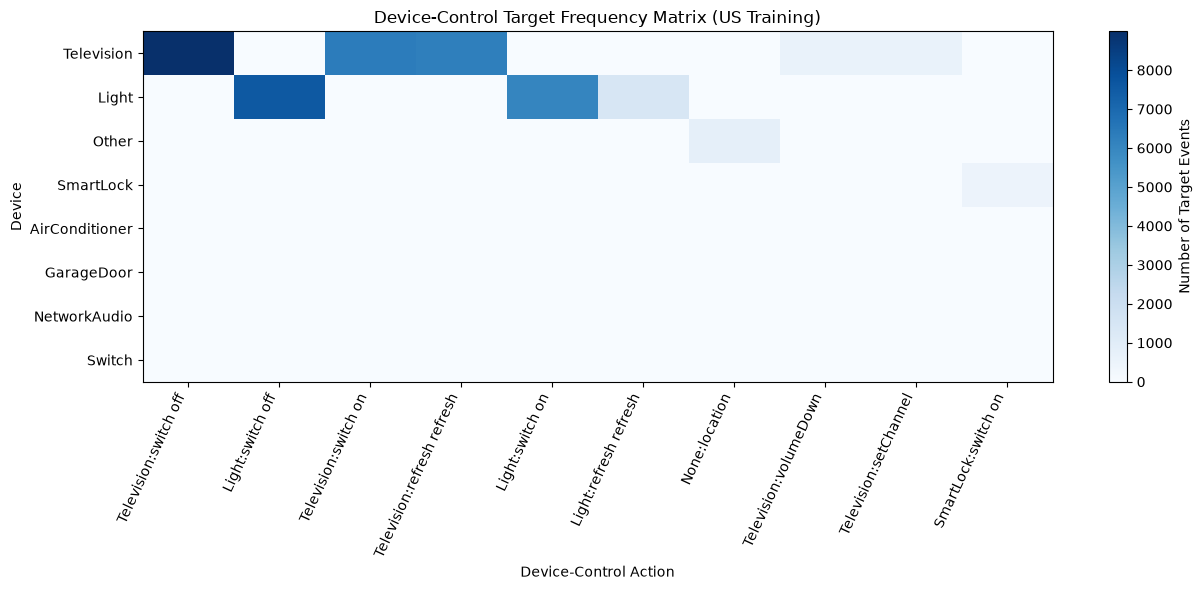

In [30]:
# Create a DataFrame of target devices and actions
target_df = pd.DataFrame({
    "Device": [
        device_reverse.get(int(x), f"Unknown:{x}")
        for x in targets[:, 2]
    ],
    "Control": [
        control_reverse.get(int(x), f"Unknown:{x}")
        for x in targets[:, 4]
    ]
})

# Find the most frequent devices and controls
top_devices = target_df["Device"].value_counts().head(8).index
top_controls = target_df["Control"].value_counts().head(10).index

# Create device x control frequency matrix
device_control_matrix = pd.crosstab(
    target_df["Device"],
    target_df["Control"]
)

device_control_matrix = device_control_matrix.reindex(
    index=top_devices,
    columns=top_controls,
    fill_value=0
)

display(device_control_matrix)

# Plot the heatmap
plt.figure(figsize=(13, 6))

plt.imshow(
    device_control_matrix,
    aspect="auto",
    cmap="Blues"
)

plt.colorbar(label="Number of Target Events")

plt.xticks(
    range(len(top_controls)),
    top_controls,
    rotation=65,
    ha="right"
)

plt.yticks(
    range(len(top_devices)),
    top_devices
)

plt.xlabel("Device-Control Action")
plt.ylabel("Device")
plt.title("Device-Control Target Frequency Matrix (US Training)")

plt.tight_layout()
plt.show()

In [31]:
# Identify refresh/status target actions
refresh_actions = target_action_names[
    action_categories == "Refresh/Status"
]

refresh_table = pd.DataFrame({
    "Action": refresh_actions.value_counts().index,
    "Count": refresh_actions.value_counts().values
})

display(refresh_table.head(10))

,Action,Count
0,Television:refresh refresh,6240
1,Light:refresh refresh,1423
2,NetworkAudio:refresh refresh,297
3,SmartLock:refresh refresh,142
4,Other:refresh refresh,67
5,AirPurifier:refresh refresh,60
6,AirConditioner:refresh refresh,31
7,Fan:refresh refresh,26
8,Computer:refresh refresh,25
9,GarageDoor:refresh refresh,14


## Extended EDA: quality, leakage, context and baselines

The following analyses are from the extended project notes. Some intentionally examine the same topic using a different unit of analysis (all window events versus prediction targets).

## Part 8 - Data Quality
# ------------------------------------------

In [ ]:
# Store the three dataset splits
splits = {
    "Training": train,
    "Validation": val,
    "Test": test
}

# Verify their structure
for name, data in splits.items():
    assert data.ndim == 3, f"{name} must be 3-dimensional"
    assert data.shape[1:] == (10, 5), (
        f"Unexpected shape for {name}: {data.shape}"
    )
    print(f"{name}: {data.shape}")

# Five encoded event columns
FEATURE_COLUMNS = [
    "day_id",
    "time_id",
    "device_id",
    "column3_id",
    "device_control_id"
]

def create_target_table(data, split_name):
    # Final event is the prediction target
    targets = data[:, -1, :]

    df = pd.DataFrame(
        targets,
        columns=FEATURE_COLUMNS
    )

    df.insert(0, "window_id", np.arange(len(data)))
    df.insert(1, "split", split_name)

    # Event immediately before the target
    df["previous_action_id"] = data[:, -2, 4]

    # Decode using existing notebook dictionaries
    df["device"] = df["device_id"].map(device_reverse)
    df["target_action"] = (
        df["device_control_id"].map(control_reverse)
    )
    df["previous_action"] = (
        df["previous_action_id"].map(control_reverse)
    )
    df["time_bin"] = df["time_id"].map(hour_reverse)
    df["day"] = df["day_id"].map(day_reverse)

    return df


train_targets = create_target_table(train, "Training")
val_targets = create_target_table(val, "Validation")
test_targets = create_target_table(test, "Test")

print("\nTarget-event counts:")
for name, df in [
    ("Training", train_targets),
    ("Validation", val_targets),
    ("Test", test_targets)
]:
    print(f"{name}: {len(df):,}")

display(train_targets.head(10))

In [ ]:
#Flatten all 10 events in each training window
flattened = train.reshape(-1,5)

#Count device-control actions
flattened_counts = (
    pd.Series(flattened[:,4]).value_counts().rename("Flattened Count")
)

#Count only target actions
target_counts = (
    train_targets["device_control_id"].value_counts().rename("Target Count")
)

comparison = pd.concat(
    [flattened_counts, target_counts],
    axis=1
).fillna(0)

comparison.index.name = "Action ID"
comparison = comparison.reset_index()

comparison["Action"] = (
    comparison["Action ID"].map(control_reverse)
)

comparison["Flattened %"] = (
    comparison["Flattened Count"]
    / len(flattened) * 100
)

comparison["Target %"] = (
    comparison["Target Count"]
    / len(train_targets) * 100
)

comparison["Difference (pp)"] = (
    comparison["Target %"] - comparison["Flattened %"]
)

comparison = comparison.sort_values(
    "Target Count",
    ascending=False
)

display(comparison.head(20).round(3))

print("Flattened events:", len(flattened))
print("Target events:", len(train_targets))

In [ ]:
from collections import Counter

def get_window_keys(data):
    return [
        tuple(window.flatten().tolist())
        for window in data
    ]

duplicate_results = []

for name, data in splits.items():
    keys = get_window_keys(data)
    counts = Counter(keys)

    duplicate_results.append({
        "Split": name,
        "Total Windows": len(keys),
        "Unique Windows": len(counts),
        "Duplicate Copies": sum(
            count - 1 for count in counts.values()
        ),
        "Windows in Duplicate Groups": sum(
            count for count in counts.values()
            if count > 1
        )
    })

duplicate_df = pd.DataFrame(duplicate_results)

duplicate_df["Duplicate %"] = (
    duplicate_df["Duplicate Copies"]
    / duplicate_df["Total Windows"] * 100
)

display(duplicate_df.round(3))

In [ ]:
reverse_mappings = {
    "day_id": day_reverse,
    "time_id": hour_reverse,
    "device_id": device_reverse,
    "device_control_id": control_reverse
}

quality_results = []

for split_name, df in [
    ("Training", train_targets),
    ("Validation", val_targets),
    ("Test", test_targets)
]:
    for column, mapping in reverse_mappings.items():

        labels = df[column].map(mapping)

        unknown = labels.isna()

        other_none = labels.fillna("").astype(str).str.contains(
            r"\b(other|none)\b",
            case=False,
            regex=True
        )

        quality_results.append({
            "Split": split_name,
            "Column": column,
            "Unknown IDs": int(unknown.sum()),
            "Unknown %": unknown.mean() * 100,
            "Other/None Count": int(other_none.sum()),
            "Other/None %": other_none.mean() * 100
        })

quality_df = pd.DataFrame(quality_results)

display(quality_df.round(3))

In [ ]:
print("Dictionary names:")
print([
    name for name, value in namespace.items()
    if name.endswith("_dict") and isinstance(value, dict)
])

print("\nFirst 10 training events:")
display(pd.DataFrame(
    train[0],
    columns=FEATURE_COLUMNS
))

print("\nColumn 3 unique values:")
print(np.unique(train[:, :, 3])[:30])

print("\nColumn 3 frequency:")
display(
    pd.Series(train[:, :, 3].flatten())
    .value_counts()
    .head(20)
)

## Part 8 - Device and device-control consistency
# ----------------------------------------------

In [ ]:
consistency_results = []

for split_name, df in [
    ("Training", train_targets),
    ("Validation", val_targets),
    ("Test", test_targets)
]:
    data = df.copy()

    # Extract device name from the combined action label
    data["action_device"] = (
        data["target_action"]
        .astype("string")
        .str.split(":", n=1)
        .str[0]
    )

    # Compare the decoded device names
    valid = (
        data["device"].notna()
        & data["target_action"].notna()
    )

    mismatches = (
        valid
        & (
            data["device"].astype("string")
            != data["action_device"]
        )
    )

    consistency_results.append({
        "Split": split_name,
        "Total Targets": len(data),
        "Comparable Targets": int(valid.sum()),
        "Mismatches": int(mismatches.sum()),
        "Mismatch %": (
            mismatches.sum() / valid.sum() * 100
            if valid.sum() else float("nan")
        )
    })

    if mismatches.any():
        print(f"\n{split_name} mismatch examples:")
        display(
            data.loc[
                mismatches,
                [
                    "device_id",
                    "device",
                    "device_control_id",
                    "target_action"
                ]
            ].head(10)
        )

consistency_df = pd.DataFrame(consistency_results)

display(consistency_df.round(3))

In [ ]:
repeat_results = []

for split_name, df in [
    ("Training", train_targets),
    ("Validation", val_targets),
    ("Test", test_targets)
]:
    repeated = (
        df["device_control_id"]
        == df["previous_action_id"]
    )

    repeat_results.append({
        "Split": split_name,
        "Total Targets": len(df),
        "Repeated Actions": int(repeated.sum()),
        "Repeat Rate %": repeated.mean() * 100
    })

repeat_df = pd.DataFrame(repeat_results)

display(repeat_df.round(3))

In [ ]:
mismatch_tables = []

for split_name, df in [
    ("Training", train_targets),
    ("Validation", val_targets),
    ("Test", test_targets)
]:
    temp = df.copy()

    temp["action_device"] = (
        temp["target_action"]
        .astype("string")
        .str.split(":", n=1)
        .str[0]
    )

    mismatch = (
        temp["device"].notna()
        & temp["action_device"].notna()
        & (
            temp["device"].astype("string")
            != temp["action_device"]
        )
    )

    summary = (
        temp.loc[mismatch]
        .groupby(["device", "action_device"])
        .size()
        .reset_index(name="Count")
    )

    summary["Split"] = split_name
    mismatch_tables.append(summary)

mismatch_summary = pd.concat(
    mismatch_tables,
    ignore_index=True
)

overall_mismatches = (
    mismatch_summary
    .groupby(["device", "action_device"])["Count"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

overall_mismatches["Share of Mismatches %"] = (
    overall_mismatches["Count"]
    / overall_mismatches["Count"].sum() * 100
)

display(overall_mismatches.head(20).round(3))

In [ ]:
# Compare the complete distributions, not just the top 20
total_variation_distance = (
    0.5
    * (
        comparison["Flattened %"]
        - comparison["Target %"]
    ).abs().sum()
)

print(
    f"Total variation distance: "
    f"{total_variation_distance:.3f} percentage points"
)

print(
    "Maximum absolute category difference:",
    round(comparison["Difference (pp)"].abs().max(), 3),
    "percentage points"
)

## Overlapping Windows
# -------------------

In [ ]:
def find_window_overlaps(data):
    """
    Find directed pairs of windows where:
    first_window[1:] == second_window[:-1]

    All 5 features of each event are compared.
    """

    # Create keys for each 9-event prefix and suffix
    prefixes = [
        window[:-1].tobytes()
        for window in data
    ]

    suffixes = [
        window[1:].tobytes()
        for window in data
    ]

    prefix_counts = Counter(prefixes)
    suffix_counts = Counter(suffixes)

    # Number of directed matching pairs
    total_pairs = sum(
        suffix_counts[key] * count
        for key, count in prefix_counts.items()
    )

    # Number of windows with a possible successor
    has_successor = sum(
        key in prefix_counts
        for key in suffixes
    )

    # Number of windows with a possible predecessor
    has_predecessor = sum(
        key in suffix_counts
        for key in prefixes
    )

    return {
        "Total Windows": len(data),
        "Windows With Successor": has_successor,
        "Successor %": 100 * has_successor / len(data),
        "Windows With Predecessor": has_predecessor,
        "Predecessor %": 100 * has_predecessor / len(data),
        "Directed Matching Pairs": total_pairs
    }


overlap_results = []

for split_name, data in splits.items():
    result = find_window_overlaps(data)
    result["Split"] = split_name
    overlap_results.append(result)

overlap_df = pd.DataFrame(overlap_results)

display(
    overlap_df[
        [
            "Split",
            "Total Windows",
            "Windows With Successor",
            "Successor %",
            "Windows With Predecessor",
            "Predecessor %",
            "Directed Matching Pairs"
        ]
    ].round(3)
)

In [ ]:
from itertools import combinations

def cross_split_overlap(data_a, data_b):
    # Full 10-event window keys
    full_a = [w.tobytes() for w in data_a]
    full_b = [w.tobytes() for w in data_b]

    # First 9 events of each window
    prefix_a = [w[:-1].tobytes() for w in data_a]
    prefix_b = [w[:-1].tobytes() for w in data_b]

    # Last 9 events of each window
    suffix_a = [w[1:].tobytes() for w in data_a]
    suffix_b = [w[1:].tobytes() for w in data_b]

    full_a_set = set(full_a)
    full_b_set = set(full_b)

    prefix_a_set = set(prefix_a)
    prefix_b_set = set(prefix_b)

    suffix_a_set = set(suffix_a)
    suffix_b_set = set(suffix_b)

    return {
        "Exact Shared Windows": len(
            full_a_set & full_b_set
        ),
        "Shared 9-Event Prefixes": len(
            prefix_a_set & prefix_b_set
        ),
        "A to B Successor Windows": sum(
            s in prefix_b_set for s in suffix_a
        ),
        "B to A Successor Windows": sum(
            s in prefix_a_set for s in suffix_b
        )
    }


cross_results = []

for name_a, name_b in combinations(splits.keys(), 2):
    result = cross_split_overlap(
        splits[name_a],
        splits[name_b]
    )

    result["Split A"] = name_a
    result["Split B"] = name_b

    cross_results.append(result)

cross_overlap_df = pd.DataFrame(cross_results)

display(
    cross_overlap_df[
        [
            "Split A",
            "Split B",
            "Exact Shared Windows",
            "Shared 9-Event Prefixes",
            "A to B Successor Windows",
            "B to A Successor Windows"
        ]
    ]
)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    overlap_df["Split"],
    overlap_df["Successor %"]
)

ax.set_title(
    "Nine-Event Window Overlap by Dataset Split"
)
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Windows With Successor (%)")

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

ax.set_ylim(
    0,
    max(overlap_df["Successor %"].max() * 1.2, 1)
)

plt.tight_layout()
plt.show()

## Part 7 - Validation and test exposure to training windows
# -------------------------------------------------

In [ ]:
def measure_split_exposure(reference, evaluation):
    ref_full = {w.tobytes() for w in reference}
    ref_prefix = {w[:-1].tobytes() for w in reference}
    ref_suffix = {w[1:].tobytes() for w in reference}

    exact = np.array([
        w.tobytes() in ref_full
        for w in evaluation
    ])

    same_history = np.array([
        w[:-1].tobytes() in ref_prefix
        for w in evaluation
    ])

    consecutive = np.array([
        (w[:-1].tobytes() in ref_suffix)
        or (w[1:].tobytes() in ref_prefix)
        for w in evaluation
    ])

    any_exposure = exact | same_history | consecutive

    return {
        "Evaluation Windows": len(evaluation),
        "Exact Match %": exact.mean() * 100,
        "Same History %": same_history.mean() * 100,
        "Consecutive Overlap %": consecutive.mean() * 100,
        "Any Exposure %": any_exposure.mean() * 100
    }


exposure_results = []

for name, evaluation in [
    ("Validation", val),
    ("Test", test)
]:
    result = measure_split_exposure(train, evaluation)
    result["Split"] = name
    exposure_results.append(result)

exposure_df = pd.DataFrame(exposure_results)

display(
    exposure_df[
        [
            "Split",
            "Evaluation Windows",
            "Exact Match %",
            "Same History %",
            "Consecutive Overlap %",
            "Any Exposure %"
        ]
    ].round(3)
)

In [ ]:
train_prefixes = {
    w[:-1].tobytes() for w in train
}
train_suffixes = {
    w[1:].tobytes() for w in train
}

validation_exposed = np.array([
    (w[:-1].tobytes() in train_suffixes)
    or (w[1:].tobytes() in train_prefixes)
    for w in val
])

validation_correct = (
    val[:, -1, 4] == val[:, -2, 4]
)

rows = []

for label, mask in [
    ("Overlapping", validation_exposed),
    ("Non-overlapping", ~validation_exposed)
]:
    count = int(mask.sum())

    rows.append({
        "Group": label,
        "Windows": count,
        "Share of Validation %": (
            100 * count / len(val)
        ),
        "Repeat-Last Accuracy %": (
            100 * validation_correct[mask].mean()
            if count else np.nan
        )
    })

overlap_accuracy_df = pd.DataFrame(rows)

display(overlap_accuracy_df.round(3))

## Part 6 - Linking Context, History, and the Next Action
# -----------------------------------------------

In [ ]:
entropy_data = train_targets[
    [
        "device_control_id",
        "previous_action_id",
        "time_id"
    ]
].copy()

entropy_data = entropy_data.rename(columns={
    "device_control_id": "target",
    "previous_action_id": "previous_action",
    "time_id": "time_bin"
})

print("Total training targets:", len(entropy_data))

print("\nUnique values:")
print("Target actions:", entropy_data["target"].nunique())
print("Previous actions:", entropy_data["previous_action"].nunique())
print("Time bins:", entropy_data["time_bin"].nunique())

print("\nMissing values:")
print(entropy_data.isna().sum())

display(entropy_data.head(10))

In [ ]:
def shannon_entropy(values):
    """Calculate Shannon entropy in bits."""
    probabilities = (
        pd.Series(values)
        .value_counts(normalize=True)
        .to_numpy()
    )

    return float(
        -(probabilities * np.log2(probabilities)).sum()
    )


def conditional_entropy(df, target, context):
    """
    Calculate empirical H(target | context).

    context may contain one or multiple columns.
    """
    total = len(df)
    result = 0.0

    for _, group in df.groupby(context, dropna=False):
        weight = len(group) / total

        result += (
            weight * shannon_entropy(group[target])
        )

    return result


# No context
H_target = shannon_entropy(entropy_data["target"])

# Previous action
H_previous = conditional_entropy(
    entropy_data,
    "target",
    ["previous_action"]
)

# Time bin
H_time = conditional_entropy(
    entropy_data,
    "target",
    ["time_bin"]
)

# Both contexts
H_both = conditional_entropy(
    entropy_data,
    "target",
    ["previous_action", "time_bin"]
)

print(f"H(Target): {H_target:.4f} bits")
print(f"H(Target | Previous): {H_previous:.4f} bits")
print(f"H(Target | Time): {H_time:.4f} bits")
print(f"H(Target | Previous, Time): {H_both:.4f} bits")

In [ ]:
entropy_results = pd.DataFrame({
    "Context": [
        "No Context",
        "Previous Action",
        "Time Bin",
        "Previous Action + Time Bin"
    ],
    "Conditional Entropy (bits)": [
        H_target,
        H_previous,
        H_time,
        H_both
    ]
})

entropy_results["Entropy Reduction (bits)"] = (
    H_target
    - entropy_results["Conditional Entropy (bits)"]
)

entropy_results["Entropy Reduction (%)"] = (
    entropy_results["Entropy Reduction (bits)"]
    / H_target * 100
    if H_target > 0 else 0.0
)

display(entropy_results.round(4))

if H_previous < H_time:
    print("\nPrevious action is more informative in training.")
elif H_time < H_previous:
    print("\nTime bin is more informative in training.")
else:
    print("\nBoth contexts have equal estimated information.")

print(
    "Additional reduction from adding time to previous action:",
    f"{H_previous - H_both:.4f} bits"
)

print(
    "Additional reduction from adding previous action to time:",
    f"{H_time - H_both:.4f} bits"
)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    entropy_results["Context"],
    entropy_results["Conditional Entropy (bits)"]
)

ax.set_title(
    "Target Action Entropy Under Different Contexts",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Available Context")
ax.set_ylabel("Conditional Entropy (bits)")

ax.set_ylim(
    0,
    max(entropy_results["Conditional Entropy (bits)"]) * 1.2
)

for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.3f} bits",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    "part6_conditional_entropy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Count unique device IDs within each window
unique_device_counts = np.array([
    len(np.unique(window[:, 2]))
    for window in train
])

device_mix_df = pd.DataFrame({
    "Unique Devices": unique_device_counts
})

device_mix_summary = (
    device_mix_df["Unique Devices"]
    .value_counts()
    .sort_index()
    .reset_index()
)

device_mix_summary.columns = [
    "Unique Devices",
    "Windows"
]

device_mix_summary["Percentage"] = (
    device_mix_summary["Windows"]
    / len(train) * 100
)

display(device_mix_summary.round(3))

mixed_device_rate = (
    unique_device_counts >= 2
).mean() * 100

print(
    f"Windows with at least 2 distinct devices: "
    f"{mixed_device_rate:.3f}%"
)

In [ ]:
print("Number of routine sequences:", len(routine_sequences))

print("\nFirst five routines:")
for i, routine in enumerate(routine_sequences[:5]):
    print(f"Routine {i + 1}:")
    print("Type:", type(routine))
    print("Content:", repr(routine)[:500])
    print()

print("First training window device IDs:")
print(train[0, :, 2])

print("\nDecoded devices:")
print([
    device_reverse.get(int(device_id), "Unknown")
    for device_id in train[0, :, 2]
])

In [ ]:
# Compare routine IDs with event-window device IDs

routine_ids = {
    int(device)
    for routine in routine_sequences
    for device in routine
}

window_ids = set(
    int(x) for x in np.unique(train[:, :, 2])
)

print("Unique routine IDs:", len(routine_ids))
print("Unique window device IDs:", len(window_ids))

print("Routine IDs not observed in training windows:")
print(sorted(routine_ids - window_ids))

print("\nRoutine IDs without device dictionary labels:")
print(sorted(
    device_id for device_id in routine_ids
    if device_id not in device_reverse
))

print("\nFirst five decoded routines:")
for routine in routine_sequences[:5]:
    print([
        device_reverse.get(int(x), f"Unknown:{x}")
        for x in routine
    ])

In [ ]:
routine_pair_counts = Counter()

for routine in routine_sequences:
    unique_devices = sorted(
        set(int(device) for device in routine)
    )

    pairs = combinations(unique_devices, 2)
    routine_pair_counts.update(pairs)

print(
    "Unique device pairs observed in routines:",
    len(routine_pair_counts)
)

routine_pair_df = pd.DataFrame(
    [
        {
            "Device A": device_reverse.get(a, str(a)),
            "Device B": device_reverse.get(b, str(b)),
            "Routine Count": count
        }
        for (a, b), count in routine_pair_counts.items()
    ]
)

routine_pair_df = routine_pair_df.sort_values(
    "Routine Count", ascending=False
)

display(routine_pair_df.head(20))

In [ ]:
observed_routine_pairs = set(routine_pair_counts)

results = []

for window in train:
    devices = sorted(
        set(int(device) for device in window[:, 2])
    )

    if len(devices) < 2:
        continue

    pairs = list(combinations(devices, 2))

    observed_count = sum(
        pair in observed_routine_pairs
        for pair in pairs
    )

    results.append({
        "Unique Devices": len(devices),
        "Total Pairs": len(pairs),
        "Observed Pairs": observed_count,
        "Unobserved Pairs": len(pairs) - observed_count,
        "All Pairs Observed": observed_count == len(pairs),
        "Any Pair Unobserved": observed_count < len(pairs),
        "No Pairs Observed": observed_count == 0
    })

window_pair_df = pd.DataFrame(results)

summary = pd.DataFrame({
    "Metric": [
        "Multi-device windows",
        "All pairs observed in routines",
        "At least one unobserved pair",
        "No pairs observed in routines"
    ],
    "Windows": [
        len(window_pair_df),
        int(window_pair_df["All Pairs Observed"].sum()),
        int(window_pair_df["Any Pair Unobserved"].sum()),
        int(window_pair_df["No Pairs Observed"].sum())
    ]
})

summary["% of Multi-Device Windows"] = (
    summary["Windows"] / len(window_pair_df) * 100
)

summary["% of All Windows"] = (
    summary["Windows"] / len(train) * 100
)

display(summary.round(3))

In [ ]:
# Generic device labels
GENERIC_DEVICES = {"None", "Other"}

# Device IDs corresponding to generic labels
generic_device_ids = {
    int(device_id)
    for device_id, label in device_reverse.items()
    if str(label) in GENERIC_DEVICES
}

print("Generic device IDs:", generic_device_ids)

# Build routine co-occurrence pairs using specific devices
specific_routine_pairs = Counter()

for routine in routine_sequences:
    devices = sorted({
        int(device)
        for device in routine
        if int(device) not in generic_device_ids
    })

    specific_routine_pairs.update(
        combinations(devices, 2)
    )

print(
    "Unique specific-device pairs in routines:",
    len(specific_routine_pairs)
)

# Compare training windows with the routine corpus
results = []

for window in train:
    devices = sorted({
        int(device)
        for device in window[:, 2]
        if int(device) not in generic_device_ids
    })

    if len(devices) < 2:
        continue

    pairs = list(combinations(devices, 2))

    observed = sum(
        pair in specific_routine_pairs
        for pair in pairs
    )

    results.append({
        "Unique Specific Devices": len(devices),
        "Total Pairs": len(pairs),
        "Observed Pairs": observed,
        "Unobserved Pairs": len(pairs) - observed,
        "All Pairs Observed": observed == len(pairs),
        "Any Pair Unobserved": observed < len(pairs),
        "No Pairs Observed": observed == 0
    })

specific_window_df = pd.DataFrame(results)

n_specific = len(specific_window_df)

specific_summary = pd.DataFrame({
    "Metric": [
        "Windows with >=2 specific devices",
        "All device pairs observed in routines",
        "At least one unobserved device pair",
        "No device pairs observed in routines"
    ],
    "Windows": [
        n_specific,
        int(specific_window_df["All Pairs Observed"].sum()),
        int(specific_window_df["Any Pair Unobserved"].sum()),
        int(specific_window_df["No Pairs Observed"].sum())
    ]
})

specific_summary["% of Eligible Windows"] = (
    specific_summary["Windows"]
    / n_specific * 100
    if n_specific else np.nan
)

specific_summary["% of All Training Windows"] = (
    specific_summary["Windows"]
    / len(train) * 100
)

display(specific_summary.round(3))

## Part 9 - Prediction Baselines and Conclusions
# -----------------------------------------

In [ ]:
# Target = final device-control action in each window
y_train = train[:, -1, 4]
y_val = val[:, -1, 4]

# Previous action = event immediately before target
previous_train = train[:, -2, 4]
previous_val = val[:, -2, 4]

# Time context of target event
time_train = train[:, -1, 1]
time_val = val[:, -1, 1]

print("Training targets:", len(y_train))
print("Validation targets:", len(y_val))

print("Unique training actions:", len(np.unique(y_train)))
print("Unique validation actions:", len(np.unique(y_val)))

print("Training time bins:", np.unique(time_train))
print("Validation time bins:", np.unique(time_val))

In [ ]:
# Identify most frequent training target
most_frequent_action = (
    pd.Series(y_train)
    .value_counts()
    .idxmax()
)

# Predict it for every validation example
pred_most_frequent = np.full(
    len(y_val),
    most_frequent_action
)

accuracy_most_frequent = (
    pred_most_frequent == y_val
).mean()

print(
    "Most frequent action:",
    control_reverse.get(
        int(most_frequent_action),
        str(most_frequent_action)
    )
)

print(
    f"Validation accuracy: "
    f"{accuracy_most_frequent * 100:.3f}%"
)

In [ ]:
# Predict the immediately previous action
pred_repeat_last = previous_val.copy()

accuracy_repeat_last = (
    pred_repeat_last == y_val
).mean()

print(
    f"Repeat-last-action validation accuracy: "
    f"{accuracy_repeat_last * 100:.3f}%"
)

print(
    "Correct predictions:",
    int((pred_repeat_last == y_val).sum())
)

In [ ]:
# Training table
time_training_df = pd.DataFrame({
    "time_bin": time_train,
    "target": y_train
})

# Most common target action for each time bin
time_prior = (
    time_training_df
    .groupby("time_bin")["target"]
    .agg(lambda x: x.value_counts().idxmax())
    .to_dict()
)

# Predict validation targets
pred_time = np.array([
    time_prior.get(
        time_bin,
        most_frequent_action
    )
    for time_bin in time_val
])

accuracy_time = (
    pred_time == y_val
).mean()

print("Time-conditioned predictions:")

for time_bin, action_id in sorted(time_prior.items()):
    print(
        f"Time bin {time_bin}: "
        f"{control_reverse.get(int(action_id), action_id)}"
    )

print(
    f"\nValidation accuracy: "
    f"{accuracy_time * 100:.3f}%"
)

In [ ]:
# Learn the most common next action
# for each previous action

previous_training_df = pd.DataFrame({
    "previous_action": previous_train,
    "target": y_train
})

previous_prior = (
    previous_training_df
    .groupby("previous_action")["target"]
    .agg(lambda x: x.value_counts().idxmax())
    .to_dict()
)

# Predict validation targets
pred_previous = np.array([
    previous_prior.get(
        action,
        most_frequent_action
    )
    for action in previous_val
])

accuracy_previous = (
    pred_previous == y_val
).mean()

print(
    "Previous-action-conditioned validation accuracy:",
    f"{accuracy_previous * 100:.3f}%"
)

print("\nExamples of learned transitions:")

for previous_id, next_id in list(previous_prior.items())[:15]:
    previous_name = control_reverse.get(
        int(previous_id), str(previous_id)
    )
    next_name = control_reverse.get(
        int(next_id), str(next_id)
    )

    print(f"{previous_name} -> {next_name}")

In [ ]:
baseline_results = pd.DataFrame({
    "Baseline": [
        "Most Frequent Action",
        "Repeat Last Action",
        "Time-Conditioned Prior",
        "Previous-Action Prior"
    ],
    "Correct Predictions": [
        int((pred_most_frequent == y_val).sum()),
        int((pred_repeat_last == y_val).sum()),
        int((pred_time == y_val).sum()),
        int((pred_previous == y_val).sum())
    ],
    "Validation Accuracy (%)": [
        accuracy_most_frequent * 100,
        accuracy_repeat_last * 100,
        accuracy_time * 100,
        accuracy_previous * 100
    ]
})

baseline_results = baseline_results.sort_values(
    "Validation Accuracy (%)",
    ascending=False
)

display(baseline_results.round(3))

print(
    "\nBest baseline:",
    baseline_results.iloc[0]["Baseline"]
)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    baseline_results["Baseline"],
    baseline_results["Validation Accuracy (%)"]
)

ax.set_title(
    "Next-Action Prediction Baselines — Validation Set"
)
ax.set_xlabel("Validation Accuracy (%)")

ax.invert_yaxis()

ax.set_xlim(
    0,
    max(baseline_results["Validation Accuracy (%)"]) * 1.2
)

for bar in bars:
    width = bar.get_width()

    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "part9_baseline_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
baseline_results["Improvement vs Repeat Last (pp)"] = (
    baseline_results["Validation Accuracy (%)"]
    - accuracy_repeat_last * 100
)

display(
    baseline_results[
        [
            "Baseline",
            "Validation Accuracy (%)",
            "Improvement vs Repeat Last (pp)"
        ]
    ].round(3)
)

In [ ]:
# Identify validation targets that differ
# from the previous action
non_repeat_mask = y_val != previous_val

prediction_sets = {
    "Most Frequent Action": pred_most_frequent,
    "Repeat Last Action": pred_repeat_last,
    "Time-Conditioned Prior": pred_time,
    "Previous-Action Prior": pred_previous
}

non_repeat_results = []

for name, predictions in prediction_sets.items():
    accuracy = (
        predictions[non_repeat_mask]
        == y_val[non_repeat_mask]
    ).mean()

    non_repeat_results.append({
        "Baseline": name,
        "Non-Repeating Targets": int(non_repeat_mask.sum()),
        "Non-Repeat Accuracy (%)": accuracy * 100
    })

non_repeat_df = pd.DataFrame(non_repeat_results)

display(non_repeat_df.round(3))

In [ ]:
# Use the final event's device-control ID as target
split_targets = {
    "Training": train[:, -1, 4],
    "Validation": val[:, -1, 4],
    "Test": test[:, -1, 4]
}

# Include every action observed in any split
all_actions = sorted(set().union(
    *(set(values.tolist()) for values in split_targets.values())
))

distribution_df = pd.DataFrame(index=all_actions)
distribution_df.index.name = "Action ID"

for name, values in split_targets.items():
    distribution_df[name] = (
        pd.Series(values)
        .value_counts(normalize=True)
        .reindex(all_actions, fill_value=0)
        * 100
    )

distribution_df["Action"] = [
    control_reverse.get(int(action_id), str(action_id))
    for action_id in distribution_df.index
]

distribution_df["Max Difference (pp)"] = (
    distribution_df[
        ["Training", "Validation", "Test"]
    ].max(axis=1)
    -
    distribution_df[
        ["Training", "Validation", "Test"]
    ].min(axis=1)
)

distribution_df = distribution_df.sort_values(
    "Training", ascending=False
)

display(distribution_df.head(20).round(3))

In [ ]:
# Top 10 actions based on training frequency
top_actions = distribution_df.head(10)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 6),
    sharey=True
)

splits_order = ["Training", "Validation", "Test"]

for ax, split_name in zip(axes, splits_order):
    ax.bar(
        top_actions["Action"],
        top_actions[split_name]
    )

    ax.set_title(split_name)
    ax.set_xlabel("Target Action")
    ax.tick_params(axis="x", rotation=70)
    ax.set_ylim(0, 22)

axes[0].set_ylabel("Percentage of Target Events")

fig.suptitle(
    "Target Action Distributions Across Dataset Splits",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "part7_target_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
distribution_comparisons = []

for split_a, split_b in combinations(
    ["Training", "Validation", "Test"], 2
):
    p = distribution_df[split_a].to_numpy() / 100
    q = distribution_df[split_b].to_numpy() / 100

    tv_distance = 0.5 * np.abs(p - q).sum()

    distribution_comparisons.append({
        "Split A": split_a,
        "Split B": split_b,
        "Total Variation Distance": tv_distance,
        "Distance (pp)": tv_distance * 100
    })

distribution_distance_df = pd.DataFrame(
    distribution_comparisons
)

display(distribution_distance_df.round(4))

In [ ]:
from collections import defaultdict
def build_overlap_graph(data):
    prefix_to_indices = defaultdict(list)
    suffix_to_indices = defaultdict(list)

    for i, window in enumerate(data):
        prefix_to_indices[window[:-1].tobytes()].append(i)
        suffix_to_indices[window[1:].tobytes()].append(i)

    successors = {}
    predecessors = {}

    for i, window in enumerate(data):
        successors[i] = prefix_to_indices.get(
            window[1:].tobytes(), []
        )
        predecessors[i] = suffix_to_indices.get(
            window[:-1].tobytes(), []
        )

    return successors, predecessors


train_successors, train_predecessors = (
    build_overlap_graph(train)
)

graph_summary = pd.DataFrame({
    "Metric": [
        "Windows with no successor",
        "Windows with one successor",
        "Windows with multiple successors",
        "Windows with no predecessor",
        "Windows with one predecessor",
        "Windows with multiple predecessors"
    ],
    "Count": [
        sum(len(v) == 0 for v in train_successors.values()),
        sum(len(v) == 1 for v in train_successors.values()),
        sum(len(v) > 1 for v in train_successors.values()),
        sum(len(v) == 0 for v in train_predecessors.values()),
        sum(len(v) == 1 for v in train_predecessors.values()),
        sum(len(v) > 1 for v in train_predecessors.values())
    ]
})

display(graph_summary)

In [ ]:
def measure_unambiguous_chains(data):
    successors, predecessors = build_overlap_graph(data)

    # Reciprocal, unique successor links
    next_window = {}

    for i, possible_next in successors.items():
        if len(possible_next) != 1:
            continue

        j = possible_next[0]

        if i == j:
            continue

        if len(predecessors[j]) == 1:
            next_window[i] = j

    incoming = set(next_window.values())
    starts = [
        i for i in range(len(data))
        if i not in incoming
    ]

    visited = set()
    chain_lengths = []
    cycle_nodes = 0

    def walk(start):
        nonlocal cycle_nodes

        current = start
        local_seen = set()
        length = 0

        while current not in visited:
            if current in local_seen:
                cycle_nodes += len(local_seen)
                break

            local_seen.add(current)
            visited.add(current)
            length += 1

            if current not in next_window:
                break

            current = next_window[current]

        if length:
            chain_lengths.append(length)

    for start in starts:
        walk(start)

    # Handle any remaining cycles
    for i in range(len(data)):
        if i not in visited:
            walk(i)

    return {
        "Total Windows": len(data),
        "Chains": len(chain_lengths),
        "Chains >= 2 Windows": sum(
            x >= 2 for x in chain_lengths
        ),
        "Chains >= 3 Windows": sum(
            x >= 3 for x in chain_lengths
        ),
        "Longest Chain (Windows)": max(chain_lengths),
        "Windows in Chains >= 2": sum(
            x for x in chain_lengths if x >= 2
        ),
        "Chain Lengths": chain_lengths
    }


chain_results = []

for name, data in splits.items():
    result = measure_unambiguous_chains(data)

    chain_results.append({
        key: value
        for key, value in result.items()
        if key != "Chain Lengths"
    } | {"Split": name})

chain_df = pd.DataFrame(chain_results)

display(chain_df)

In [ ]:
# Examine the relationship between column 3,
# device IDs, and device-control IDs.

all_target_events = pd.concat(
    [
        train_targets,
        val_targets,
        test_targets
    ],
    ignore_index=True
)

column3_summary = (
    all_target_events
    .groupby("column3_id")
    .agg(
        Events=("window_id", "size"),
        Unique_Devices=("device_id", "nunique"),
        Unique_Actions=("device_control_id", "nunique")
    )
    .reset_index()
    .sort_values("Events", ascending=False)
)

display(column3_summary.head(30))

# Does each device-control ID have a single column 3 ID?
action_to_column3 = (
    all_target_events
    .groupby("device_control_id")["column3_id"]
    .nunique()
)

# Does each device-control ID have a single device ID?
action_to_device = (
    all_target_events
    .groupby("device_control_id")["device_id"]
    .nunique()
)

print(
    "Action IDs associated with multiple column 3 values:",
    int((action_to_column3 > 1).sum())
)

print(
    "Action IDs associated with multiple device IDs:",
    int((action_to_device > 1).sum())
)

print("\nExamples:")
display(
    all_target_events[
        [
            "device_id",
            "column3_id",
            "device_control_id",
            "device",
            "target_action"
        ]
    ].drop_duplicates().head(30)
)

In [ ]:
quality_issues = pd.DataFrame([
    {
        "Issue": "Duplicate windows",
        "Evidence": (
            "305 training, 24 validation, "
            "53 test duplicate copies"
        ),
        "Impact": (
            "Repeated observations may affect "
            "frequency estimates and effective sample size"
        )
    },
    {
        "Issue": "Cross-split overlap",
        "Evidence": (
            "87.951% of validation windows have "
            "a nine-event consecutive match with training"
        ),
        "Impact": (
            "Potential evaluation dependence; "
            "not proof of shared user events"
        )
    },
    {
        "Issue": "Device/action disagreement",
        "Evidence": (
            "1,756 of 67,882 target events "
            "have differing device labels (2.587%)"
        ),
        "Impact": (
            "Device-specific interpretations may "
            "depend on encoding conventions"
        )
    },
    {
        "Issue": "Generic categories",
        "Evidence": (
            "Training targets: 4.211% generic device "
            "labels; 3.738% generic action labels"
        ),
        "Impact": (
            "Limits the specificity of "
            "device-level analysis"
        )
    },
    {
        "Issue": "Window flattening",
        "Evidence": (
            "Total variation distance of 0.00831 "
            "versus target-only action distribution"
        ),
        "Impact": (
            "Marginal action frequencies are similar, "
            "but overlap can affect dependence"
        )
    },
    {
        "Issue": "Coarse time bins",
        "Evidence": "Time encoded in three-hour intervals",
        "Impact": (
            "Cannot resolve exact event times "
            "or fine-grained temporal patterns"
        )
    },
    {
        "Issue": "Missing calendar dates",
        "Evidence": (
            "No full calendar date in the "
            "five analyzed event columns"
        ),
        "Impact": (
            "Cannot directly study seasonal trends "
            "or calendar-specific changes"
        )
    },
    {
        "Issue": "Unverified fourth feature",
        "Evidence": (
            "Column 3 has no identified "
            "decoding dictionary"
        ),
        "Impact": (
            "Full device-control consistency "
            "cannot yet be established"
        )
    }
])

display(quality_issues)

fig, ax = plt.subplots(figsize=(15, 7))
ax.axis("off")

table = ax.table(
    cellText=quality_issues.values,
    colLabels=quality_issues.columns,
    loc="center",
    cellLoc="left",
    colWidths=[0.19, 0.37, 0.44]
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2.5)

plt.savefig(
    "part8_data_quality_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Build conditional probability tables from training data

probability_data = train_targets[
    [
        "device_control_id",
        "previous_action_id",
        "time_id"
    ]
].copy()

# P(Target | Previous Action)
p_target_given_previous = pd.crosstab(
    probability_data["previous_action_id"],
    probability_data["device_control_id"],
    normalize="index"
)

# P(Target | Time Bin)
p_target_given_time = pd.crosstab(
    probability_data["time_id"],
    probability_data["device_control_id"],
    normalize="index"
)

# P(Target | Previous Action, Time Bin)
p_target_given_both = (
    probability_data
    .groupby(
        [
            "previous_action_id",
            "time_id",
            "device_control_id"
        ]
    )
    .size()
    .rename("Count")
    .reset_index()
)

p_target_given_both["Probability"] = (
    p_target_given_both["Count"]
    /
    p_target_given_both.groupby(
        ["previous_action_id", "time_id"]
    )["Count"].transform("sum")
)

print("P(Target | Previous Action):")
display(p_target_given_previous.iloc[:10, :10].round(3))

print("\nP(Target | Time Bin):")
display(p_target_given_time.iloc[:, :10].round(3))

print("\nP(Target | Previous Action, Time Bin):")
display(p_target_given_both.head(20).round(3))

In [ ]:
# Select the 10 most frequent training target actions
top_action_ids = (
    train_targets["device_control_id"]
    .value_counts()
    .head(10)
    .index
)

# Time-conditioned probabilities for top actions
readable_time_probs = (
    p_target_given_time
    .reindex(columns=top_action_ids, fill_value=0)
    .copy()
)

readable_time_probs.columns = [
    control_reverse.get(int(x), str(x))
    for x in readable_time_probs.columns
]

readable_time_probs.index = [
    hour_reverse.get(int(x), str(x))
    for x in readable_time_probs.index
]

display((readable_time_probs * 100).round(2))

# Previous-action probabilities for common previous actions
top_previous_ids = (
    train_targets["previous_action_id"]
    .value_counts()
    .head(10)
    .index
)

readable_previous_probs = (
    p_target_given_previous
    .reindex(
        index=top_previous_ids,
        columns=top_action_ids,
        fill_value=0
    )
    .copy()
)

readable_previous_probs.index = [
    control_reverse.get(int(x), str(x))
    for x in readable_previous_probs.index
]

readable_previous_probs.columns = [
    control_reverse.get(int(x), str(x))
    for x in readable_previous_probs.columns
]

display((readable_previous_probs * 100).round(2))

In [ ]:
# Check sparsity of previous-action + time combinations

context_counts = (
    train_targets
    .groupby(["previous_action_id", "time_id"])
    .size()
    .rename("Observations")
    .reset_index()
)

sparsity_summary = pd.DataFrame({
    "Metric": [
        "Total context combinations",
        "Combinations with 1 observation",
        "Combinations with fewer than 5",
        "Combinations with fewer than 10",
        "Combinations with at least 30"
    ],
    "Count": [
        len(context_counts),
        int((context_counts["Observations"] == 1).sum()),
        int((context_counts["Observations"] < 5).sum()),
        int((context_counts["Observations"] < 10).sum()),
        int((context_counts["Observations"] >= 30).sum())
    ]
})

display(sparsity_summary)

print("\nObservations per context:")
display(context_counts["Observations"].describe())

## Part 9: Combined previous-action and time baseline

combined_training_df = pd.DataFrame({
    "previous_action": previous_train,
    "time_bin": time_train,
    "target": y_train
})

# Most frequent target for each combined context
combined_prior = (
    combined_training_df
    .groupby(["previous_action", "time_bin"])["target"]
    .agg(lambda x: x.value_counts().idxmax())
    .to_dict()
)

# Predict validation actions
# Fallback: previous-action prior, then global prior
pred_combined = np.array([
    combined_prior.get(
        (previous, time_bin),
        previous_prior.get(previous, most_frequent_action)
    )
    for previous, time_bin in zip(previous_val, time_val)
])

combined_accuracy = (
    pred_combined == y_val
).mean() * 100

print(
    f"Combined-context accuracy: {combined_accuracy:.3f}%"
)

print(
    "Previous-action prior accuracy:",
    f"{accuracy_previous * 100:.3f}%"
)

print(
    "Improvement:",
    f"{combined_accuracy - accuracy_previous * 100:+.3f} pp"
)

# Check how often validation contexts were unseen
unseen_contexts = sum(
    (previous, time_bin) not in combined_prior
    for previous, time_bin in zip(previous_val, time_val)
)

print(
    "Validation contexts unseen during training:",
    unseen_contexts
)
print(
    "Unseen context rate:",
    f"{unseen_contexts / len(y_val) * 100:.3f}%"
)

In [ ]:
# Investigate relationships between column 3 and action labels

analysis_df = all_target_events.copy()

# Extract action text after the first colon
analysis_df["action_operation"] = (
    analysis_df["target_action"]
    .astype("string")
    .str.split(":", n=1)
    .str[1]
)

# Count operations associated with each column 3 value
column3_operations = (
    analysis_df
    .groupby(["column3_id", "action_operation"])
    .size()
    .reset_index(name="Count")
)

# Find the most common operations for each column 3 value
column3_operations = (
    column3_operations
    .sort_values(
        ["column3_id", "Count"],
        ascending=[True, False]
    )
)

display(
    column3_operations
    .groupby("column3_id")
    .head(5)
    .head(60)
)

# Count distinct operations for each column 3 ID
operation_diversity = (
    analysis_df
    .groupby("column3_id")["action_operation"]
    .nunique()
    .reset_index(name="Unique Operations")
)

display(operation_diversity.head(35))

In [ ]:
# Test whether device + column3 uniquely determines action

mapping_check = (
    all_target_events
    .groupby(["device_id", "column3_id"])
    ["device_control_id"]
    .nunique()
    .reset_index(name="Unique Actions")
)

ambiguous_mappings = mapping_check[
    mapping_check["Unique Actions"] > 1
]

print("Total device + column3 combinations:", len(mapping_check))
print("Combinations mapping to multiple actions:", len(ambiguous_mappings))

print(
    "Percentage ambiguous:",
    round(
        len(ambiguous_mappings) / len(mapping_check) * 100,
        3
    )
)

display(
    ambiguous_mappings
    .sort_values("Unique Actions", ascending=False)
    .head(20)
)